<a href="https://colab.research.google.com/github/Hellohiavinash/Machine_Learning_Projects/blob/main/Ecommerce_case_study_project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [97]:
!pip install -q gdown
!gdown --folder 'https://drive.google.com/drive/folders/1Qt1HfSoTyCKiyDy2frR-hYOT9UvfwGq7' -O /content/data

Retrieving folder contents
Processing file 1rqihT647UW9HEmERxCrTJrcZZ9xE5TEi CustomersData.xlsx
Processing file 1u2gedRtVaCqTQNylaohI9WO6m3pA8rnc Dataset Description.docx
Processing file 1CfORUKckP7Qi9swmCe8XEgLLWnpKl4eE Discount_Coupon.csv
Processing file 1hjHgCluvPEUfrp9w-_-73ch0d9SK6FHf Marketing_Spend.csv
Processing file 1ZvQn7-UtGSdJa3H9zM4ve_uzACFAzF0Z Online_Sales.csv
Processing file 1tqJmtKcfhiEJXYVV21ybnD4UaXYW9r4v Tax_amount.xlsx
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1rqihT647UW9HEmERxCrTJrcZZ9xE5TEi
To: /content/data/CustomersData.xlsx
100% 42.2k/42.2k [00:00<00:00, 44.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1u2gedRtVaCqTQNylaohI9WO6m3pA8rnc
To: /content/data/Dataset Description.docx
100% 9.06k/9.06k [00:00<00:00, 19.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1CfORUKckP7Qi9swmCe8XEgLLWnpKl4eE
To: /content/data/Discount_Coup

**Business Story:**
An e-commerce company sold products online across five US locations in 2019: 1,468 customers, about 26.6K transactions and 5.40M in revenue. Its goals are to acquire customers consistently, retain them, and spend marketing and discount money where it returns the most.
This notebook cleans and merges five datasets (customers, sales, tax, coupons and marketing spend), then answers 20 business questions across acquisition, retention, revenue, discounts, marketing, customer value, statistical testing and seasonality. Each answer has the calculation, a chart, an insight and a recommendation.
Data cleaning note: 400 transactions had no coupon defined for that month and category, so their discount was treated as 0. Invoice value = quantity x price x (1 - discount) x (1 + GST) + delivery charge.

In [98]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [99]:
p='/content/data/'
cust    = pd.read_excel(p+'CustomersData.xlsx')
tax     = pd.read_excel(p+'Tax_amount.xlsx')
coupon  = pd.read_csv(p+'Discount_Coupon.csv')
mkt     = pd.read_csv(p+'Marketing_Spend.csv')
sales   = pd.read_csv(p+'Online_Sales.csv')

In [100]:
for name, d in [('cust',cust),('tax',tax),('coupon',coupon),('mkt',mkt),('sales',sales)]:
  print('=====',name,d.shape)
  print(d.head(3).to_string())
  print(d.dtypes)
  print()

===== cust (1468, 4)
   CustomerID Gender    Location  Tenure_Months
0       17850      M     Chicago             12
1       13047      M  California             43
2       12583      M     Chicago             33
CustomerID        int64
Gender           object
Location         object
Tenure_Months     int64
dtype: object

===== tax (20, 2)
  Product_Category   GST
0         Nest-USA  0.10
1           Office  0.10
2          Apparel  0.18
Product_Category     object
GST                 float64
dtype: object

===== coupon (204, 4)
  Month Product_Category Coupon_Code  Discount_pct
0   Jan          Apparel      SALE10            10
1   Feb          Apparel      SALE20            20
2   Mar          Apparel      SALE30            30
Month               object
Product_Category    object
Coupon_Code         object
Discount_pct         int64
dtype: object

===== mkt (365, 3)
       Date  Offline_Spend  Online_Spend
0  1/1/2019           4500       2424.50
1  1/2/2019           4500       3480

In [101]:
sales['Transaction_Date'] = pd.to_datetime(sales['Transaction_Date'],format='%m/%d/%Y')
mkt['Date']               = pd.to_datetime(mkt['Date'],format='%m/%d/%Y')
sales['Month']            = sales['Transaction_Date'].dt.strftime('%b')
sales['MonthNum']         = sales['Transaction_Date'].dt.month


In [102]:
df = sales.merge(cust,on = 'CustomerID',how='left')
df = df.merge(tax, on = 'Product_Category',how='left')
df = df.merge(coupon,on = ['Month','Product_Category'],how='left')

In [103]:
print(df['Coupon_Status'].unique())
import numpy as np

['Used' 'Not Used' 'Clicked']


In [104]:
df['Discount_pct'] = np.where(df['Coupon_Status']=='Used',df['Discount_pct'],0)
df['Discount_pct'] = df['Discount_pct'].fillna(0)

In [105]:
df['Invoice_Value'] = (df['Quantity'] * df['Avg_Price'] * (1-df['Discount_pct']/100) * (1+df['GST']) + df['Delivery_Charges'] )

In [106]:
print(df.shape)
print(df.isna().sum())
df.head()

(52924, 19)
CustomerID               0
Transaction_ID           0
Transaction_Date         0
Product_SKU              0
Product_Description      0
Product_Category         0
Quantity                 0
Avg_Price                0
Delivery_Charges         0
Coupon_Status            0
Month                    0
MonthNum                 0
Gender                   0
Location                 0
Tenure_Months            0
GST                      0
Coupon_Code            400
Discount_pct             0
Invoice_Value            0
dtype: int64


,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status,Month,MonthNum,Gender,Location,Tenure_Months,GST,Coupon_Code,Discount_pct,Invoice_Value
0,17850,16679,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,Jan,1,M,Chicago,12,0.10,ELEC10,10.0,158.6729
1,17850,16680,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,Jan,1,M,Chicago,12,0.10,ELEC10,10.0,158.6729
2,17850,16681,2019-01-01,GGOEGFKQ020399,Google Laptop and Cell Phone Stickers,Office,1,2.05,6.5,Used,Jan,1,M,Chicago,12,0.10,OFF10,10.0,8.5295
3,17850,16682,2019-01-01,GGOEGAAB010516,Google Men's 100% Cotton Short Sleeve Hero Tee...,Apparel,5,17.53,6.5,Not Used,Jan,1,M,Chicago,12,0.18,SALE10,0.0,109.9270
4,17850,16682,2019-01-01,GGOEGBJL013999,Google Canvas Tote Natural/Navy,Bags,1,16.50,6.5,Used,Jan,1,M,Chicago,12,0.18,AIO10,10.0,24.0230


In [107]:
df['Coupon_Code'] = df['Coupon_Code'].fillna('No Coupon')


In [108]:
print(df.isna().sum())

CustomerID             0
Transaction_ID         0
Transaction_Date       0
Product_SKU            0
Product_Description    0
Product_Category       0
Quantity               0
Avg_Price              0
Delivery_Charges       0
Coupon_Status          0
Month                  0
MonthNum               0
Gender                 0
Location               0
Tenure_Months          0
GST                    0
Coupon_Code            0
Discount_pct           0
Invoice_Value          0
dtype: int64


In [109]:
import calendar as cl
mlabels = [cl.month_abbr[i] for i in range(1,13)]
print(mlabels)
first = df.groupby('CustomerID')['Transaction_Date'].min().rename('First_Date').reset_index()
first.head()

['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


,CustomerID,First_Date
0,12346,2019-09-15
1,12347,2019-03-24
2,12348,2019-06-22
3,12350,2019-12-14
4,12356,2019-09-15


Jan    215
Feb     96
Mar    177
Apr    163
May    112
Jun    137
Jul     94
Aug    135
Sep     78
Oct     87
Nov     68
Dec    106
Name: count, dtype: int64
Highest: Jan 215 | Lowest: Nov 68


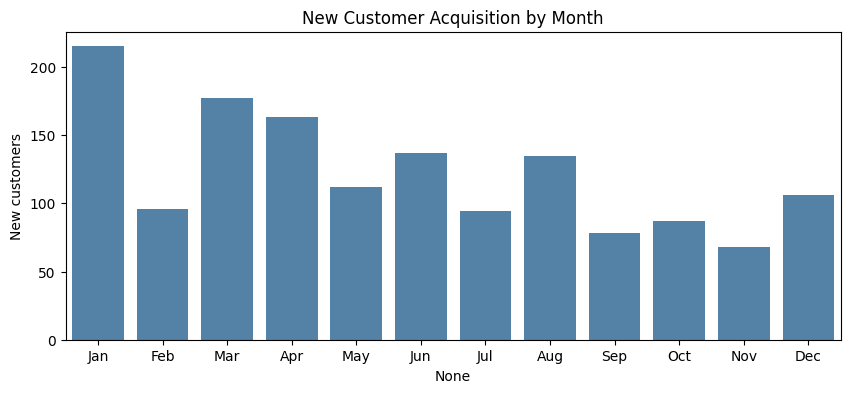

Q1    488
Q2    412
Q3    307
Q4    261
Name: count, dtype: int64


In [110]:

df = df.drop(columns=['First_Date','First_MonthNum','Cust_Type'],errors='ignore')
mlabels = [cl.month_abbr[i] for i in range(1,13)]

first = df.groupby('CustomerID')['Transaction_Date'].min().rename('First_Date')
df = df.merge(first,on='CustomerID',how='left')
df['First_MonthNum'] = df['First_Date'].dt.month
df['Cust_Type'] = np.where(df['MonthNum']==df['First_MonthNum'],'New','Existing')

acq = df.drop_duplicates('CustomerID')['First_MonthNum'].value_counts().sort_index()
acq.index = [mlabels[i-1] for i in acq.index]
print(acq)
print('Highest:',acq.idxmax(),acq.max(),'| Lowest:',acq.idxmin(),acq.min())

plt.figure(figsize=(10,4))

sns.barplot(x=acq.index,y=acq.values,color='steelblue')
plt.title('New Customer Acquisition by Month')
plt.ylabel('New customers')
plt.show()

q = acq.groupby(np.arange(len(acq))//3).sum()
q.index=['Q1','Q2','Q3','Q4']
print(q)



**1.Identify the months with the highest and lowest acquisition count. What strategies could be implemented to address the fluctuations and ensure consistent growth throughout the year**
**2.Analyze the data to determine if certain months consistently show higher or lower monthly acquisitions. How can the company capitalize on high-performing months and improve performance during slower periods?**
Q1 Insight: January has the highest acquisition (215 new customers) while November has the lowest (68), a ~3x gap. Acquisition is front-loaded: Q1 brought 488 customers and Q4 only 261, a ~47% decline across the year. Month-to-month swings are sharp (Jan 215 → Feb 96 → Mar 177), so growth is inconsistent.
Q1 Recommendations: (1) Run "New Year" style campaigns in weak months (Feb, Sep, Nov) with first-purchase coupons. (2) Shift marketing budget towards Sep-Nov to stop the H2 decline. (3) Use referral programs and remarketing to smooth out the zigzag instead of depending on a few peak months.
Q2 Insight: Yes, there is a seasonal pattern. Jan, Mar, Apr, Jun and Aug are the high months, while Feb, May, Jul, Sep and Nov are low. H1 delivers ~61% of all new customers versus ~39% in H2. (Only one year of data is available, so this is a 2019 pattern that should be validated with more years.)
Q2 Recommendations: Double down on the high months with more inventory and ad spend, and use low months for retention campaigns, loyalty rewards and flash sales to keep the engine running.

Feb     6.0
Mar    10.1
Apr    11.5
May    11.2
Jun    18.5
Jul    22.4
Aug    27.5
Sep    14.7
Oct    15.0
Nov    14.8
Dec    14.9
dtype: float64
Strongest: Aug 27.5 | Weakest: Feb 6.0


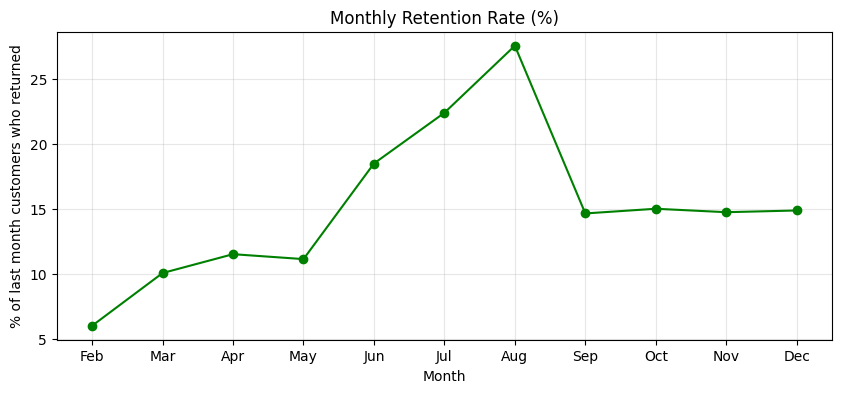

     customers  orders    revenue  coupon_used_pct  orders_per_cust  \
Jan        215    2102  494090.55            34.04             9.78   
Feb        109    1664  375162.05            33.43            15.27   
Mar        208    1991  415157.79            33.96             9.57   
Apr        224    1813  477498.59            34.46             8.09   
May        200    2034  365596.03            32.63            10.17   
Jun        259    1940  361000.17            33.84             7.49   
Jul        236    2080  451878.41            33.46             8.81   
Aug        300    2414  475796.88            34.03             8.05   
Sep        193    1932  396510.49            34.75            10.01   
Oct        210    2125  480767.37            33.86            10.12   
Nov        188    2282  547788.13            34.44            12.14   
Dec        236    2684  556112.29            33.14            11.37   

     avg_order_value  
Jan           235.06  
Feb           225.46  
Mar    

In [111]:
### Q3: Month-over-month retention
active = df.groupby('MonthNum')['CustomerID'].apply(set)
ret = {}
for m in range(2,13):
  ret[mlabels[m-1]]= len(active[m-1] & active[m])/ len(active[m-1]) * 100
ret=pd.Series(ret)
print(ret.round(1))
print('Strongest:',ret.idxmax(),round(ret.max(),1),'| Weakest:',ret.idxmin(),round(ret.min(),1))

plt.figure(figsize=(10,4))
plt.plot(ret.index,ret.values,marker='o',color='green')
plt.title('Monthly Retention Rate (%)')
plt.xlabel('Month')
plt.ylabel('% of last month customers who returned')
plt.grid(alpha=.3)
plt.show()

### Q4: Behaviour per month

beh= df.groupby('MonthNum').agg(
    customers = ('CustomerID','nunique'),
    orders = ('Transaction_ID','nunique'),
    revenue = ('Invoice_Value','sum'),
    coupon_used_pct = ('Coupon_Status',lambda s:(s=='Used').mean()*100)
)

beh['orders_per_cust']= beh['orders']/beh['customers']
beh['avg_order_value'] = beh['revenue']/beh['orders']
beh.index=mlabels
print(beh.round(2))

top_months = list(ret.sort_values(ascending=False).head(3).index)
print('Top retention months:',top_months)
d=df[df['Month'].isin(top_months)]
print(d.groupby('Product_Category')['Invoice_Value'].sum().sort_values(ascending=False).head(5).round(0))



**Q3:Identify periods with the strongest and weakest retention rates. What strategies could be implemented to improve retention during weaker months?
Q4:Analyze customer behavior during high-retention months and suggest ways to replicate this success throughout the year.**
Q3 Insight: Retention is low overall. In an average month only about 1 in 6 customers from the previous month buys again. It is weakest in February (6%) and strongest in August (28%). It climbs steadily from Feb to Aug, drops sharply in September to ~16%, and then stays flat at ~16% through December.
Q3 Recommendations: (1) Run post-purchase journeys (email or WhatsApp at day 7, 14 and 30) in the weak months, especially Feb-May. (2) Use targeted repeat-purchase coupons for first-time buyers instead of blanket discounts, since coupon usage is flat at ~33% every month. (3) Investigate what changed after August and extend the Jun-Aug tactics into Sep-Dec.
Q4 Insight: The top-retention months are Aug, Jul and Jun. They have the most active customers (300, 236 and 259 vs. ~210 in other months). But orders per customer are among the lowest (7.5-8.8 vs. 9-15 elsewhere) and average order value is moderate (186-217). Coupon usage is the same ~33-34% as other months, so discounts do not explain the retention. Nest-USA brings ~50% and Apparel ~18% of revenue in these months.
Q4 Recommendations: (1) Build the summer campaign around Nest-USA and Apparel as hero categories and replicate it in Sep-Dec. (2) Add cross-sell bundles (Nest-USA with Office or Drinkware) to raise basket size in these high-traffic months. (3) Keep the same engagement cadence after August, when retention fell from 28% to 16%.

Cust_Type  Existing       New
Jan             0.0  494091.0
Feb         46525.0  328637.0
Mar         68930.0  346228.0
Apr        195986.0  281513.0
May        132339.0  233257.0
Jun        143666.0  217335.0
Jul        271516.0  180363.0
Aug        246913.0  228884.0
Sep        234032.0  162479.0
Oct        223293.0  257474.0
Nov        313157.0  234632.0
Dec        292697.0  263415.0


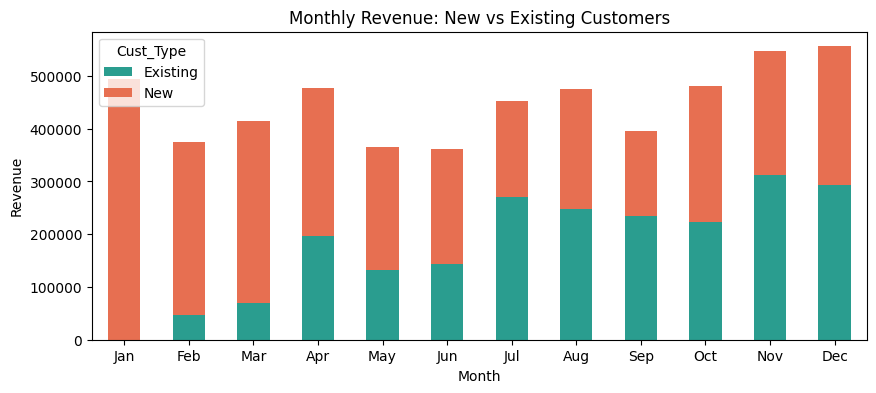

Cust_Type  Existing    New
Jan             0.0  100.0
Feb            12.4   87.6
Mar            16.6   83.4
Apr            41.0   59.0
May            36.2   63.8
Jun            39.8   60.2
Jul            60.1   39.9
Aug            51.9   48.1
Sep            59.0   41.0
Oct            46.4   53.6
Nov            57.2   42.8
Dec            52.6   47.4


In [112]:
### Q5 New vs Existing reveune
rev = df.pivot_table(index='MonthNum',columns='Cust_Type',values='Invoice_Value',aggfunc='sum')
rev.index = mlabels
rev=rev.fillna(0)
print(rev.round(0))

rev.plot(kind='bar',stacked=True,figsize=(10,4),color=['#2a9d8f','#e76f51'])
plt.title('Monthly Revenue: New vs Existing Customers')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.show()

print((rev.div(rev.sum(axis=1), axis=0)*100).round(1))

**Q5:Compare the revenue generated by new and existing customers month-over-month. What does this trend suggest about the balance between acquisition and retention efforts?**
Insight: New customers generate ~60% of revenue (3.23M) and existing customers ~40% (2.17M) of the 5.40M total. The existing-customer share grows from ~12% in Feb to ~60% in Jul and stays at 46-59% in Aug-Dec, with Nov-Dec existing revenue at ~300K, about 6x Feb. Acquisition is falling (488 new customers in Q1 vs. 261 in Q4), yet new-customer revenue holds at 160-260K per month because revenue per new customer rises from ~2.3K in Jan to ~3.5K in Nov.Recommendation: The business has shifted from acquisition-led to retention-led growth. But retention is flat at ~16% while acquisition declines, so the base that drives revenue is not being refilled. Protect the existing base with loyalty and win-back programs, and restore acquisition in Sep-Nov.Note: January shows 100% new revenue because the dataset starts in January, so every customer is "new" by construction.

               transactions     revenue  avg_invoice  avg_qty  rev_share_%
Coupon_Status                                                             
Clicked               26926  2925734.30       108.66     4.45        54.21
Not Used               8094   897317.65       110.86     4.38        16.63
Used                  17904  1574306.80        87.93     4.62        29.17
Total discount given: 310772
Discount as % of gross: 6.65
              transactions    revenue  avg_invoice  avg_qty
Discount_pct                                               
0.0                    126   11869.75        94.20     4.21
10.0                  5933  584948.90        98.59     4.91
20.0                  6000  512685.08        85.45     4.47
30.0                  5845  464803.08        79.52     4.50
                        revenue  coupon_used_pct  discount_amt  \
Product_Category                                                 
Nest-USA              2721645.8             33.6      170560.8   
Apparel  

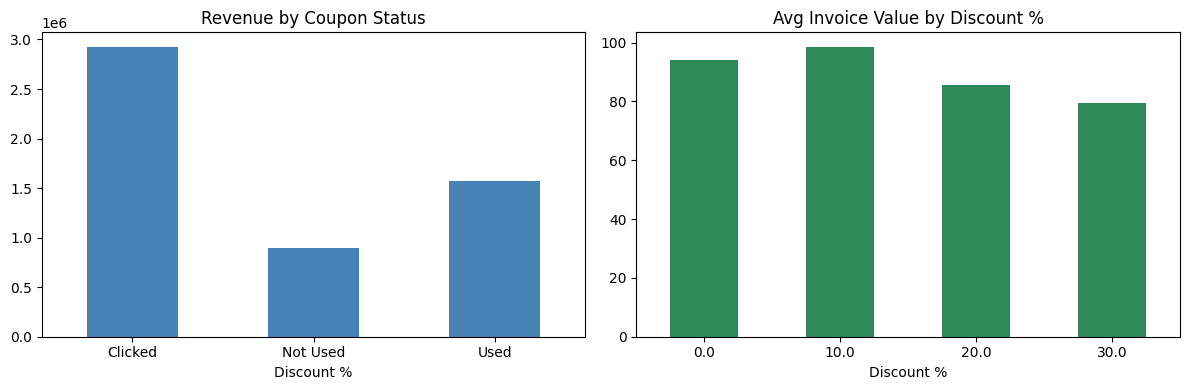

In [113]:
### Q6: Coupon usage vs revenue
df['Gross_Value'] = df['Quantity'] * df['Avg_Price']
df['Discount_Amt'] = df['Gross_Value'] * df['Discount_pct'] /100

coup = df.groupby('Coupon_Status').agg(
    transactions=('Transaction_ID','count'),
    revenue=('Invoice_Value','sum'),
    avg_invoice=('Invoice_Value','mean'),
    avg_qty=('Quantity','mean')
)
coup['rev_share_%']=coup['revenue']/coup['revenue'].sum()*100
print(coup.round(2))
print('Total discount given:',round(df['Discount_Amt'].sum()))
print('Discount as % of gross:',round(df['Discount_Amt'].sum()/ df['Gross_Value'].sum()*100,2))

used = df[df['Coupon_Status']=='Used']
lvl =used.groupby('Discount_pct').agg(
    transactions=('Transaction_ID','count'),
    revenue=('Invoice_Value','sum'),
    avg_invoice=('Invoice_Value','mean'),
    avg_qty = ('Quantity','mean')
)
print(lvl.round(2))

cat = df.groupby('Product_Category').agg(
    revenue=('Invoice_Value','sum'),
    coupon_used_pct=('Coupon_Status',lambda s:(s=='Used').mean()*100),
    discount_amt=('Discount_Amt','sum')
)
cat['discount_%_of_rev']=cat['discount_amt']/cat['revenue']*100
print(cat.sort_values('revenue',ascending=False).round(1).head(10))

fig,ax= plt.subplots(1,2,figsize=(12,4))
coup['revenue'].plot(kind='bar',ax=ax[0],color='steelblue')
ax[0].set_title('Revenue by Coupon Status')
ax[0].set_xlabel('Discount %')
ax[0].tick_params(axis='x',rotation=0)

lvl['avg_invoice'].plot(kind='bar',ax=ax[1],color='seagreen')
ax[1].set_title('Avg Invoice Value by Discount %')
ax[1].set_xlabel('Discount %')
ax[1].tick_params(axis='x',rotation=0)
plt.tight_layout()
plt.show()


**Q6 :Analyze the relationship between coupon usage and revenue generation. How can discount strategies be optimized to maximize revenue while maintaining profitability? :**
Q6 Insight: Coupons were used in 33.8% of transactions (17,904) and generated 1.57M, about 29% of revenue. Coupon users' average invoice is 87.9 vs 110.9 for non-users, about 21% lower, even though they buy slightly more units per line item (4.62 vs 4.38). Total discount given is 310.8K (6.65% of gross value, about 5.8% of revenue). Deeper discounts do not grow the basket: the 10% coupon has the highest average invoice (98.6) and quantity (4.91), while 30% has the lowest (79.5, 4.50), and uptake is the same at every level (5.8-6.0K transactions each). Coupon usage is 33% in every category (30-36%), so coupons are not targeted. Nest-USA absorbs 55% of all discount money (170.6K). Discount as % of category revenue is highest for Headgear (9.5%) and Nest (7.2%).
Q6 Recommendations: (1) Make 10% the default coupon and test removing the 30% tier. (2) Cap discounts on Headgear and Nest, which have the heaviest discount burden relative to revenue. (3) Use coupons to drive basket size (for example "10% off above a threshold") instead of blanket offers.
Assumption: no cost or margin data is available, so discount as % of gross value is used as the profitability proxy.

                                        Product_Description Product_Category   revenue   qty  orders  avg_price  coupon_used_pct
316  Nest Learning Thermostat 3rd Gen-USA - Stainless Steel         Nest-USA  731870.7  4570    3511      151.0             34.3
312                  Nest Cam Outdoor Security Camera - USA         Nest-USA  671620.1  5206    3328      121.8             32.8
310                   Nest Cam Indoor Security Camera - USA         Nest-USA  567867.5  4402    3230      120.2             32.0
321         Nest Protect Smoke + CO White Battery Alarm-USA         Nest-USA  229033.0  2683    1361       79.8             33.8
323           Nest Protect Smoke + CO White Wired Alarm-USA         Nest-USA  225275.9  2670    1065       79.7             37.0
317            Nest Learning Thermostat 3rd Gen-USA - White         Nest-USA  215902.4  1368    1089      149.6             35.2
324             Nest Secure Alarm System Starter Pack - USA             Nest  177939.6   510     

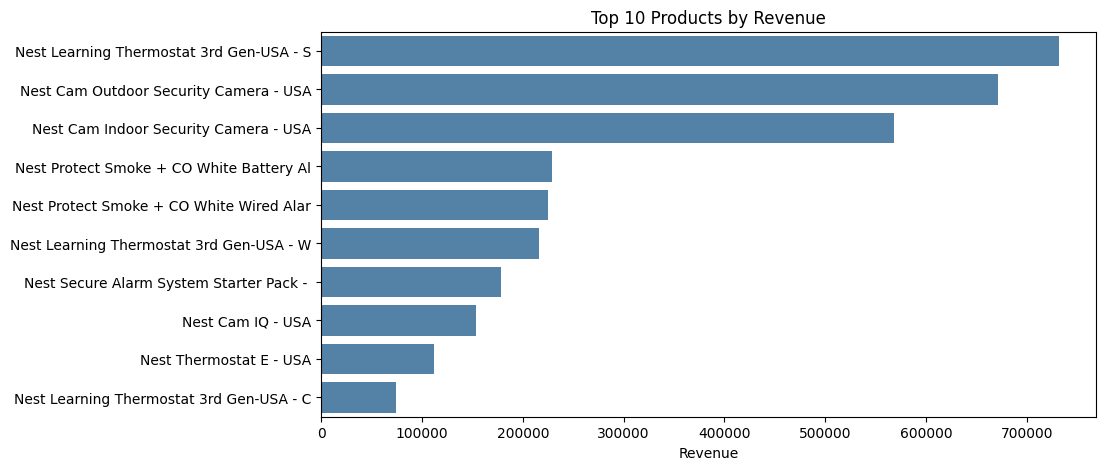

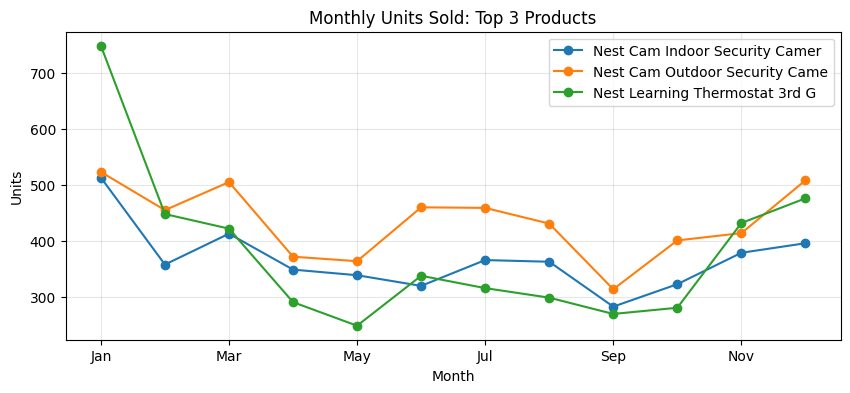

In [114]:
### Q7 top prdoucts
prod =df.groupby(['Product_Description','Product_Category']).agg(
    revenue=('Invoice_Value','sum'),
    qty=('Quantity','sum'),
    orders=('Transaction_ID','nunique'),
    avg_price=('Avg_Price','mean'),
    coupon_used_pct=('Coupon_Status',lambda s:(s=='Used').mean()*100)

).reset_index()

top=prod.sort_values('revenue',ascending=False).head(10)
print(top.round(1).to_string())
print('Top 10 Products share of revenue %:',round(top['revenue'].sum()/prod['revenue'].sum()*100,1))

plt.figure(figsize=(10,5))
sns.barplot(y=top['Product_Description'].str[:40],x=top['revenue'],color='steelblue')
plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('')
plt.show()

top3 = top['Product_Description'].head(3).tolist()
tm = df[df['Product_Description'].isin(top3)].pivot_table(
    index='MonthNum',columns='Product_Description',values='Quantity',aggfunc='sum')
tm.index = mlabels
tm.columns=[c[:30] for c in tm.columns]
tm.plot(figsize=(10,4),marker='o')
plt.title('Monthly Units Sold: Top 3 Products')
plt.xlabel('Month')
plt.ylabel('Units')
plt.grid(alpha=.3)
plt.show()



**Q7: Identify the top-performing products and analyze the factors driving their success. How can this insight inform inventory management and promotional strategies?**
Q7 Insight: Revenue is highly concentrated. The top 10 products give 58.5% of revenue, and all 10 are Nest products. The top 3 (Learning Thermostat 3rd Gen Stainless Steel 0.73M, Nest Cam Outdoor 672K, Nest Cam Indoor 568K) alone contribute about 36%. Monthly units for all three peak in January (the thermostat at 750 units), fall to a trough around May (thermostat) and September (cameras), then recover strongly in Nov-Dec (~390-510 units). The thermostat is the most volatile of the three.
Q7 Recommendations: (1) Never run out of stock on the top 3, especially before Nov-Dec. (2) Bundle the thermostat and cameras with slower products (Smoke + CO alarms, Secure Alarm Starter Pack) to lift the mid-tier. (3) Reduce dependence on a few SKUs by promoting non-Nest categories like Apparel (2nd-largest category, 828K) in the weak May and Sep periods.

     Offline_Spend  Online_Spend  Total_Spend    Revenue  Revenue_per_Spend
Jan          96600      58328.95    154928.95  494090.55               3.19
Feb          81300      55807.92    137107.92  375162.05               2.74
Mar          73500      48750.09    122250.09  415157.79               3.40
Apr          96000      61026.83    157026.83  477498.59               3.04
May          65500      52759.64    118259.64  365596.03               3.09
Jun          80500      53818.14    134318.14  361000.17               2.69
Jul          67500      52717.85    120217.85  451878.41               3.76
Aug          85500      57404.15    142904.15  475796.88               3.33
Sep          83000      52514.54    135514.54  396510.49               2.93
Oct          93500      57724.65    151224.65  480767.37               3.18
Nov          93000      68144.96    161144.96  547788.13               3.40
Dec         122000      76648.75    198648.75  556112.29               2.80
Corr total s

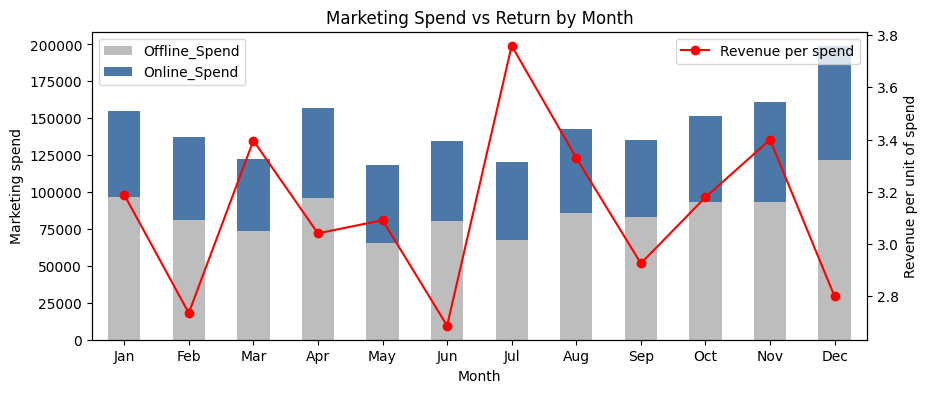

In [115]:
### Q8 Spend vs Revenue
mkt['MonthNum'] = mkt['Date'].dt.month
ms = mkt.groupby('MonthNum')[['Offline_Spend','Online_Spend']].sum()
ms['Total_Spend']=ms['Offline_Spend']+ms['Online_Spend']
ms['Revenue'] = df.groupby('MonthNum')['Invoice_Value'].sum()
ms['Revenue_per_Spend']=ms['Revenue']/ms['Total_Spend']
ms.index=mlabels

print(ms.round(2))
print('Corr total spend vs revenue:',round(ms['Total_Spend'].corr(ms['Revenue']),3))
print('Best months:',ms['Revenue_per_Spend'].nlargest(3).round(2).to_dict())
print('Worst months:',ms['Revenue_per_Spend'].nsmallest(3).round(2).to_dict())

fig,ax1= plt.subplots(figsize=(10,4))
ms[['Offline_Spend','Online_Spend']].plot(kind='bar',stacked=True,ax=ax1,color=['#bdbdbd','#4c78a8'])
ax1.set_xlabel('Month')
ax1.set_ylabel('Marketing spend')
ax1.tick_params(axis='x',rotation=0)

ax2 = ax1.twinx()

ax2.plot(range(12),ms['Revenue_per_Spend'].values,color='red',marker='o',label='Revenue per spend')
ax2.set_ylabel('Revenue per unit of spend')
ax2.legend(loc='upper right')
plt.title('Marketing Spend vs Return by Month')
plt.show()




**Q8: Analyze the relationship between monthly marketing spend and revenue. Are there any months where marketing efforts yielded disproportionately high or low returns? How can marketing strategies be adjusted to improve ROI?**
Q8 Insight: Total spend was ~1.73M against 5.40M revenue, an overall return of ~3.1 revenue per unit of spend. Offline is ~60% of spend and online ~40%. Spend and revenue move together at the monthly level (correlation 0.80). The best-return months are Jul (3.76), Nov (3.40) and Mar (3.40). The worst are Jun (2.69), Feb (2.74) and Dec (2.80). December has the highest spend (198.6K, +23% over Nov) but revenue rose only ~1.5% (547.8K to 556.1K), so returns fell sharply. July got strong revenue (452K) on one of the lowest budgets (120K).
Q8 Recommendations: (1) Cap spend near the Oct-Nov level, since the extra December budget bought almost no extra revenue. (2) Study what worked in July and March (low spend, high return) and replicate it in Jun and Feb. (3) Shift budget from low-return months to the months with the highest return.


In [116]:
import statsmodels.api as sm

               Offline_Spend  Online_Spend  Total_Spend  Revenue
Offline_Spend          1.000         0.351        0.853    0.098
Online_Spend           0.351         1.000        0.789    0.074
Total_Spend            0.853         0.789        1.000    0.106
Revenue                0.098         0.074        0.106    1.000
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          1.218e+04   1332.652      9.143      0.000    9563.367    1.48e+04
Offline_Spend     0.6356      0.434      1.465      0.144      -0.218       1.489
Online_Spend      0.4176      0.511      0.817      0.414      -0.587       1.422
R-squared: 0.011


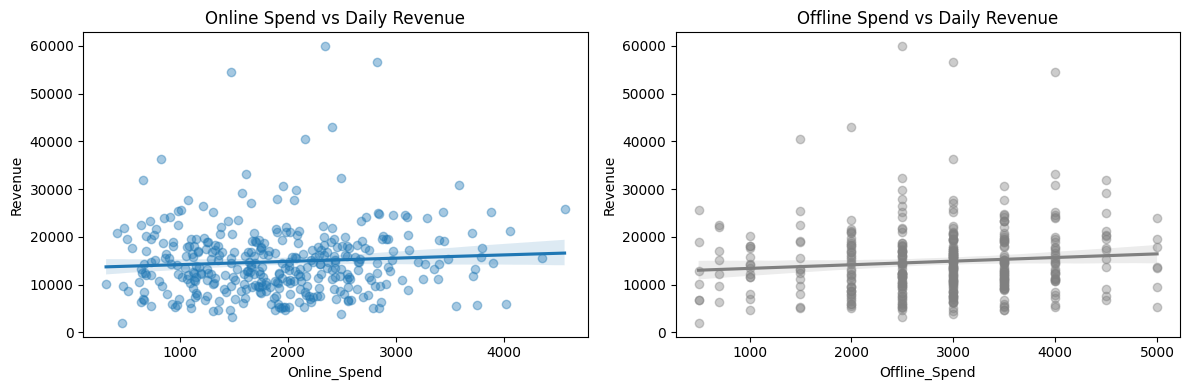

In [117]:
### Q9 campaign effectiveness
daily_rev=df.groupby('Transaction_Date')['Invoice_Value'].sum().rename('Revenue')
dd=mkt.set_index('Date').join(daily_rev)
dd['Revenue'] = dd['Revenue'].fillna(0)
dd['Total_Spend']=dd['Offline_Spend'] + dd['Online_Spend']
print(dd[['Offline_Spend','Online_Spend','Total_Spend','Revenue']].corr().round(3))


X = sm.add_constant(dd[['Offline_Spend','Online_Spend']])
res = sm.OLS(dd['Revenue'],X).fit()
print(res.summary().tables[1])
print('R-squared:',round(res.rsquared,3))

fig, ax = plt.subplots(1,2,figsize=(12,4))

sns.regplot(x='Online_Spend',y='Revenue',data=dd,ax=ax[0],scatter_kws={'alpha':.4})
ax[0].set_title('Online Spend vs Daily Revenue')
sns.regplot(x='Offline_Spend',y='Revenue',data=dd,ax=ax[1],scatter_kws={'alpha':.4},color='gray')
ax[1].set_title('Offline Spend vs Daily Revenue')
plt.tight_layout()
plt.show()

**Q9: Evaluate the effectiveness of marketing campaigns by comparing marketing spend to revenue generated. Are there opportunities to reallocate resources for better results?**
Q9 Insight: At the daily level, marketing spend explains very little of revenue. Correlation with daily revenue is 0.10 (offline), 0.07 (online) and 0.11 (total). The regression gives R² = 0.011. The offline coefficient is 0.64 (p = 0.144) and online is 0.42 (p = 0.414), so neither is statistically significant. The strong monthly correlation (0.80) is mostly because the budget is raised in high-demand months (Nov-Dec), so it reflects seasonality and not proof that spend causes revenue (it is also only 12 data points). Offline is directionally a bit more productive per unit than online, but the difference is not significant.
**Q9 Recommendations:** (1) Do not scale spend on the assumption it drives sales one-for-one. Run controlled tests (geo or time-based holdouts). (2) Track campaign-level attribution (channel, creative, coupon code) to see what actually converts. (3) Review the online budget, since it shows the weakest link to revenue.


          customers  avg_recency  avg_frequency  avg_monetary    revenue
Segment                                                                 
Premium         408         63.4           40.3        8449.7  3447457.6
Gold            312        142.2           18.4        3800.8  1185855.9
Silver          341        154.3            8.8        1572.9   536363.2
Standard        407        222.3            3.5         559.4   227682.1


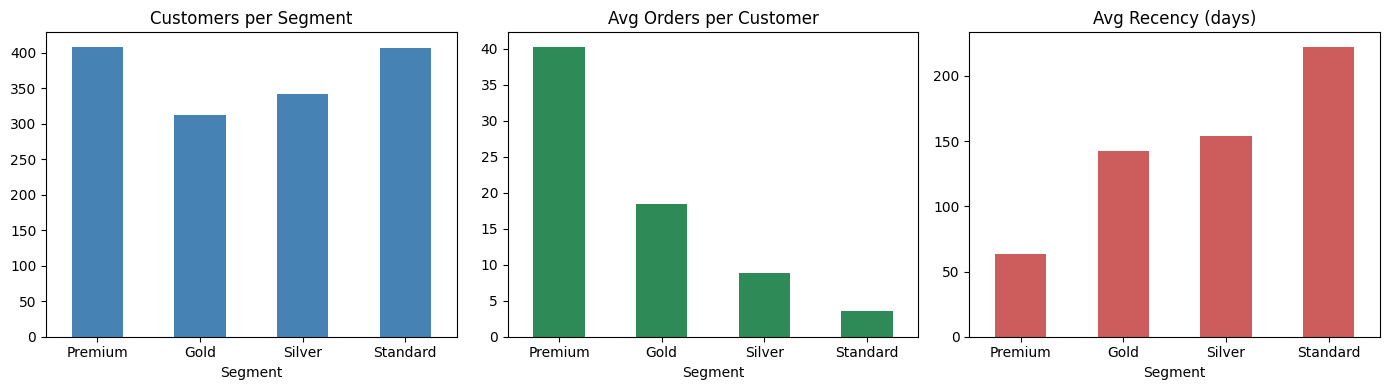

In [118]:
### Q10 : RFM
snapshot = df['Transaction_Date'].max() + pd.Timedelta(days=1)
rfm = df.groupby('CustomerID').agg(
    Recency=('Transaction_Date', lambda x: (snapshot - x.max()).days),
    Frequency=('Transaction_ID', 'nunique'),
    Monetary=('Invoice_Value', 'sum'))

rfm['R'] = pd.qcut(rfm['Recency'].rank(method='first'), 4, labels=[4,3,2,1]).astype(int)
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1,2,3,4]).astype(int)
rfm['M'] = pd.qcut(rfm['Monetary'].rank(method='first'), 4, labels=[1,2,3,4]).astype(int)
rfm['Score'] = rfm['R'] + rfm['F'] + rfm['M']
rfm['Segment'] = pd.cut(rfm['Score'], bins=[0,5,7,9,12],
                        labels=['Standard','Silver','Gold','Premium'])

seg = rfm.groupby('Segment').agg(
    customers=('Score','count'),
    avg_recency=('Recency','mean'),
    avg_frequency=('Frequency','mean'),
    avg_monetary=('Monetary','mean'),
    revenue=('Monetary','sum')).loc[['Premium','Gold','Silver','Standard']]
print(seg.round(1))

fig, ax = plt.subplots(1,3, figsize=(14,4))
seg['customers'].plot(kind='bar', ax=ax[0], color='steelblue'); ax[0].set_title('Customers per Segment')
seg['avg_frequency'].plot(kind='bar', ax=ax[1], color='seagreen'); ax[1].set_title('Avg Orders per Customer')
seg['avg_recency'].plot(kind='bar', ax=ax[2], color='indianred'); ax[2].set_title('Avg Recency (days)')
for a in ax: a.set_xlabel('Segment'); a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Q10 : Segment customers into groups such as Premium, Gold, Silver, and Standard. What targeted strategies can be developed for each segment to improve retention and revenue? (Use RFM segmentation techniques)**
Q10 Insight: Customers were scored 1-4 on Recency, Frequency and Monetary value and grouped into four segments by total score (3-5 Standard, 6-7 Silver, 8-9 Gold, 10-12 Premium). Premium customers (408) buy ~40 times on average, spend ~8,450 each and last bought ~63 days before the snapshot. Gold (312) buy 18 times and spend ~3,800 (recency 142 days). Silver (341) buy ~9 times and spend ~1,573 (recency 154 days). Standard (407) buy ~3.5 times, spend ~559 and last bought ~222 days ago. A Premium customer is worth ~15x a Standard customer, and recency worsens steadily down the tiers.
**Q10 Recommendations:** (1) Protect Premium with early access, loyalty rewards and a dedicated service. (2) Move Gold to Premium with targeted upsell and bundles. (3) Run win-back campaigns for Silver and Standard, whose last purchase was 5-7 months ago.


          customers  cust_share_%    revenue  rev_share_%
Segment                                                  
Premium         408          27.8  3447457.6         63.9
Gold            312          21.3  1185855.9         22.0
Silver          341          23.2   536363.2          9.9
Standard        407          27.7   227682.1          4.2


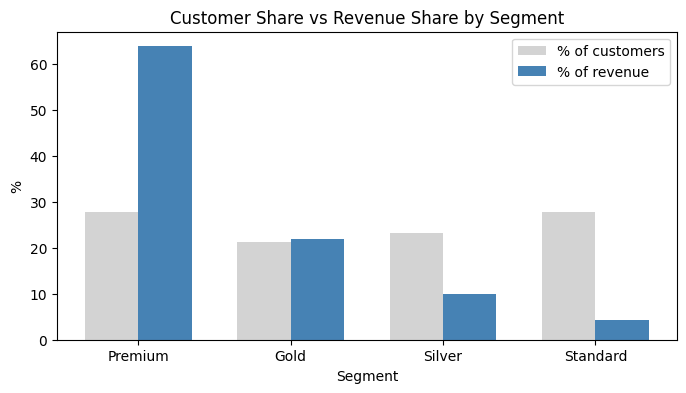

In [119]:
### Q11 revenue contribution
seg['cust_share_%'] = seg['customers']/seg['customers'].sum()*100
seg['rev_share_%'] = seg['revenue']/seg['revenue'].sum()*100
print(seg[['customers','cust_share_%','revenue','rev_share_%']].round(1))

x = np.arange(4); w = 0.35
plt.figure(figsize=(8,4))
plt.bar(x-w/2, seg['cust_share_%'], w, label='% of customers', color='lightgray')
plt.bar(x+w/2, seg['rev_share_%'], w, label='% of revenue', color='steelblue')
plt.xticks(x, seg.index); plt.ylabel('%'); plt.xlabel('Segment')
plt.title('Customer Share vs Revenue Share by Segment'); plt.legend(); plt.show()


**Q11: Analyze the revenue contribution of each customer segment. How can the company focus its efforts on high-value segments while nurturing lower-value segments?**
Q11 Insight: Revenue is heavily concentrated. Premium is 27.8% of customers but 63.9% of revenue (3.45M). Gold is 21.3% of customers and 22.0% of revenue (1.19M). Silver is 23.2% of customers and 9.9% of revenue. Standard is 27.7% of customers but only 4.2% of revenue (228K). Premium and Gold together are ~49% of customers and ~86% of revenue.
**Q11 Recommendations:** (1) Put the retention budget on Premium and Gold, since losing a few of them costs more than losing many Standard customers. (2) Do not spend heavily on discounts for Standard. Use low-cost automated email and WhatsApp journeys for them. (3) Track the Premium count monthly as a key health metric.


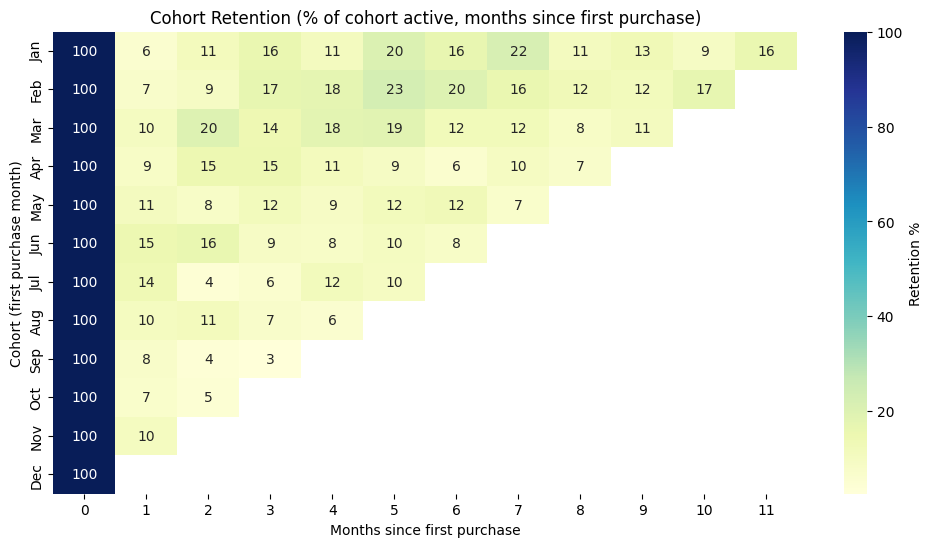

Cohort size:
 First_MonthNum
Jan    215.0
Feb     96.0
Mar    177.0
Apr    163.0
May    112.0
Jun    137.0
Jul     94.0
Aug    135.0
Sep     78.0
Oct     87.0
Nov     68.0
Dec    106.0
Name: 0, dtype: float64

Avg retention after month 0 (%):
 Jan    13.7
Feb    15.0
Mar    13.9
Apr    10.2
May    10.1
Jun    10.9
Jul     9.1
Aug     8.7
Sep     4.7
Oct     5.7
Nov    10.3
Dec     NaN
dtype: float64

Highest: Feb 15.0 | Lowest: Sep 4.7
Month-1 retention (%):
 Jan     6.0
Feb     7.3
Mar    10.2
Apr     8.6
May    10.7
Jun    14.6
Jul    13.8
Aug    10.4
Sep     7.7
Oct     6.9
Nov    10.3
Dec     NaN
Name: 1, dtype: float64


In [120]:
### Q12: cohort retention
cohort = df[['CustomerID','MonthNum','First_MonthNum']].drop_duplicates()
cohort['Period'] = cohort['MonthNum'] - cohort['First_MonthNum']
cp = cohort.pivot_table(index='First_MonthNum', columns='Period',
                        values='CustomerID', aggfunc='nunique')
cohort_size = cp[0]
ret_mat = cp.div(cohort_size, axis=0)*100
ret_mat.index = [mlabels[i-1] for i in ret_mat.index]

plt.figure(figsize=(12,6))
sns.heatmap(ret_mat.round(1), annot=True, fmt='.0f', cmap='YlGnBu',
            cbar_kws={'label':'Retention %'})
plt.title('Cohort Retention (% of cohort active, months since first purchase)')
plt.xlabel('Months since first purchase'); plt.ylabel('Cohort (first purchase month)')
plt.show()

avg_ret = ret_mat.iloc[:, 1:].mean(axis=1) # average over all later months
m1_ret = ret_mat[1]
print('Cohort size:\n', cohort_size.rename(index=lambda i: mlabels[i-1]))
print('\nAvg retention after month 0 (%):\n', avg_ret.round(1))
print('\nHighest:', avg_ret.idxmax(), round(avg_ret.max(),1),
      '| Lowest:', avg_ret.idxmin(), round(avg_ret.min(),1))
print('Month-1 retention (%):\n', m1_ret.round(1))

**Q12: Group customers by their month of first purchase and analyze retention rates over time. Which cohorts exhibit the highest and lowest retention rates? What strategies can be implemented to improve retention for weaker cohorts?**
Q12 Insight: Cohort retention is low. Only ~6-15% of a cohort returns in the month after first purchase, and later months mostly stay between 5% and 23%. The best average retention after month 0 is for the February cohort (15.0%), followed by Mar (13.9%) and Jan (13.7%). The worst is the September cohort (4.7%), followed by Oct (5.7%). Month-1 retention improves from 6.0% (Jan) to a peak of 14.6% (Jun) and 13.8% (Jul), then falls to 7.7% (Sep) and 6.9% (Oct). Some cohorts show a second wave of returns, for example Feb at month 5 (23%) and Mar at month 2 (20%), which suggests repeat buying is event-driven.
**Q12 Recommendations:** (1) Build a first-30-day journey (welcome offer, product tips, reminder) to lift month-1 retention from the 6-10% range. (2) Study what the Feb-Mar and Jun-Jul acquisition campaigns did differently and repeat it for Sep-Oct. (3) Time reactivation campaigns around the months where past cohorts returned.
Note: later cohorts have fewer observed months (Nov has only month 1, Oct only months 1-2), so their averages are less reliable than earlier cohorts.

     customers  avg_ltv  avg_first3m
Jan        215   5709.0       2790.0
Feb         96   6626.0       3683.0
Mar        177   4346.0       2468.0
Apr        163   3211.0       2009.0
May        112   3449.0       2282.0
Jun        137   2428.0       1796.0
Jul         94   2955.0       2184.0
Aug        135   2238.0       1875.0
Sep         78   2155.0       2146.0
Oct         87   3114.0       3114.0
Nov         68   3523.0       3523.0
Dec        106   2485.0       2485.0
Best LTV: Feb | Lowest LTV: Sep
Best first-3-month value: Feb | Lowest: Jun


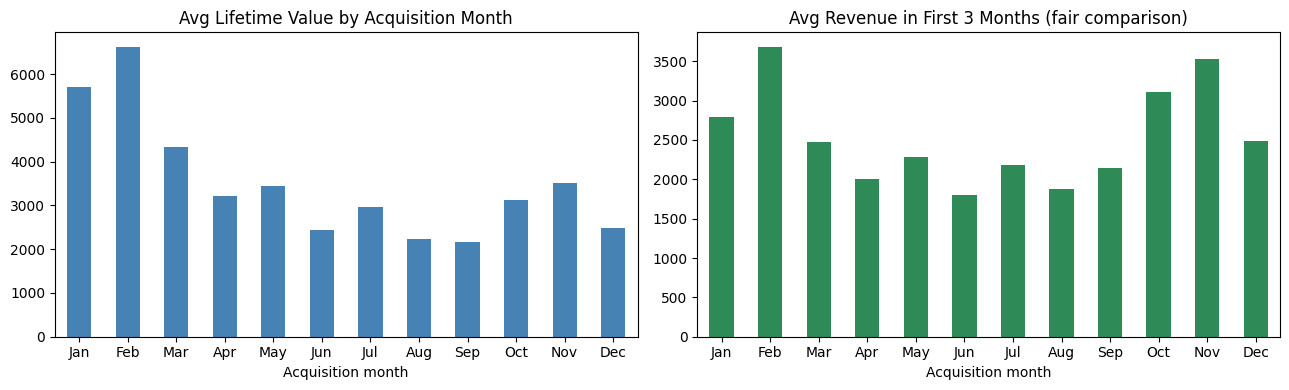

In [121]:
### Q13: LTV by acquisition month
cust_rev = df.groupby('CustomerID')['Invoice_Value'].sum().rename('Total_Revenue')
first_m = df.drop_duplicates('CustomerID').set_index('CustomerID')['First_MonthNum']
ltv = pd.concat([cust_rev, first_m], axis=1)
# fair comparison: revenue within first 3 months of each customer's life
early = df[(df['MonthNum'] - df['First_MonthNum']) <= 2].groupby('CustomerID')['Invoice_Value'].sum().rename('Rev_First3M')
ltv = ltv.join(early)

ltv_m = ltv.groupby('First_MonthNum').agg(
    customers=('Total_Revenue','count'),
    avg_ltv=('Total_Revenue','mean'),
    avg_first3m=('Rev_First3M','mean'))
ltv_m.index = mlabels
print(ltv_m.round(0))
print('Best LTV:', ltv_m['avg_ltv'].idxmax(), '| Lowest LTV:', ltv_m['avg_ltv'].idxmin())
print('Best first-3-month value:', ltv_m['avg_first3m'].idxmax(), '| Lowest:', ltv_m['avg_first3m'].idxmin())
fig, ax = plt.subplots(1,2, figsize=(13,4))
ltv_m['avg_ltv'].plot(kind='bar', ax=ax[0], color='steelblue')
ax[0].set_title('Avg Lifetime Value by Acquisition Month')
ltv_m['avg_first3m'].plot(kind='bar', ax=ax[1], color='seagreen')
ax[1].set_title('Avg Revenue in First 3 Months (fair comparison)')
for a in ax:
   a.set_xlabel('Acquisition month')
   a.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Q13:Analyze the lifetime value of customers acquired in different months. How can this insight inform acquisition and retention strategies?**
Q13 Insight: Observed lifetime value in 2019 is highest for February-acquired customers (6,626), followed by Jan (5,709) and Mar (4,346), and lowest for Sep (2,155) and Aug (2,238). Early cohorts partly look better simply because they had more months to buy. On the fair comparison of revenue in the first 3 months, Feb is still the best (3,683), but Nov (3,523, only 2 months observed) and Oct (3,114) beat most mid-year cohorts, which sit around 1,800-2,300 (lowest: Jun at 1,796). So the late-year cohorts are high-value customers, even though acquisition volume is low in those months.
**Q13 Recommendations:** (1) Invest in acquisition in Oct-Nov, where fewer customers arrive but each is worth more. (2) Review the mid-year (Jun-Sep) acquisition channels and offers, since they bring the lowest-value customers. (3) Replicate the February approach, which gives the highest value per customer.

(26631, 11)
         Invoice                  Gross                   Qty             
           count    mean  median  count    mean median  count  mean median
Coupon                                                                    
Clicked    13619  210.30  139.93  13619  174.02  119.0  13619  8.95    2.0
Not Used    4051  215.93  139.93   4051  180.10  119.0   4051  9.18    2.0
Used        8961  185.09  123.43   8961  175.34  119.0   8961  8.82    2.0
Welch t-test: t=-3.691, p=0.0002255
Mann-Whitney U: p=3.478e-20
Cohen's d: -0.073
Gross value Used vs Not Used: p = 0.5272
ANOVA across all 3 coupon states: p = 0.0


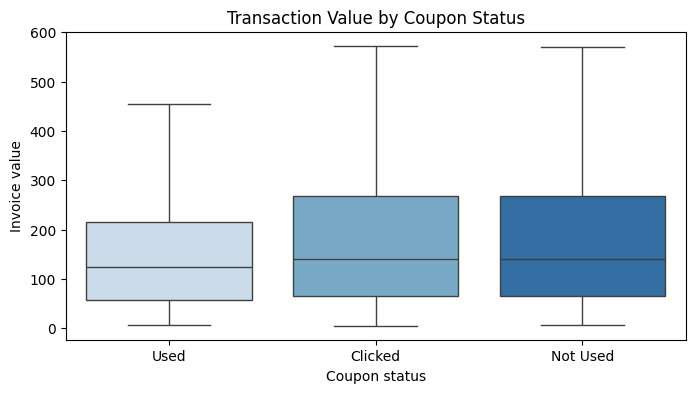

In [122]:
from scipy import stats
df['Gross_Value'] = df['Quantity']*df['Avg_Price']


txn = df.groupby(['CustomerID','Transaction_ID','Transaction_Date']).agg(
    Invoice=('Invoice_Value','sum'), Gross=('Gross_Value','sum'),
    Qty=('Quantity','sum'), Delivery=('Delivery_Charges','sum'),
    Coupon=('Coupon_Status','first'), MonthNum=('MonthNum','first'),
    Location=('Location','first'), Gender=('Gender','first')).reset_index()
print(txn.shape)

### Q14
print(txn.groupby('Coupon')[['Invoice','Gross','Qty']].agg(['count','mean','median']).round(2))

used = txn.loc[txn.Coupon=='Used','Invoice']
notused = txn.loc[txn.Coupon=='Not Used','Invoice']
t, p = stats.ttest_ind(used, notused, equal_var=False)
u, pu = stats.mannwhitneyu(used, notused)
d = (used.mean()-notused.mean())/np.sqrt((used.var()+notused.var())/2)
print(f"Welch t-test: t={t:.3f}, p={p:.4g}")
print(f"Mann-Whitney U: p={pu:.4g}")
print(f"Cohen's d: {d:.3f}")

# same test on pre-discount value (is it the discount or the basket?)
g1 = txn.loc[txn.Coupon=='Used','Gross']; g2 = txn.loc[txn.Coupon=='Not Used','Gross']
print("Gross value Used vs Not Used: p =", round(stats.ttest_ind(g1, g2, equal_var=False)[1],4))

# 3-group ANOVA (Used / Not Used / Clicked)
groups = [g['Invoice'].values for _, g in txn.groupby('Coupon')]
print("ANOVA across all 3 coupon states: p =", round(stats.f_oneway(*groups)[1],4))

plt.figure(figsize=(8,4))
sns.boxplot(x='Coupon', y='Invoice', data=txn, showfliers=False, palette='Blues')
plt.title('Transaction Value by Coupon Status'); plt.xlabel('Coupon status'); plt.ylabel('Invoice value')
plt.show()

**Q14: Do customers who use coupons have a different average transaction value compared to those who do not?Conduct a statistical test to validate this hypothesis. What implications does this have for the company’s discount and coupon strategies?**
Hypothesis: H0: average transaction value is the same for coupon users and non-users. H1: it differs.
Insight: Coupon users (8,961 transactions) have an average invoice of 185.09 vs 215.93 for non-users (4,051), about 14% lower (median 123.4 vs 139.9). The difference is statistically significant (Welch t-test p = 0.0002, Mann-Whitney p < 0.001), but the effect size is negligible (Cohen's d = -0.07). Before discount, the basket value is the same (gross 175.3 vs 180.1, p = 0.53) and median quantity is 2 in both groups. So the gap comes from the discount itself, not from smaller baskets, and coupons are not making customers buy more. Customers who only clicked (13,619) look like non-users (210.30).
Implications: (1) Coupons reduce revenue per transaction without growing the basket, so blanket coupons are not paying for themselves. (2) Tie discounts to behaviour: a minimum basket value or "buy 2, get X% off". (3) Use coupons for new or lapsed customers, and do not give them to customers who would have bought anyway.

               Orders    AOV   Spend
Location                            
California       17.4  188.6  3596.1
Chicago          20.4  193.6  4115.2
New Jersey       15.4  198.9  3139.3
New York         17.2  200.2  3362.8
Washington DC    18.9  220.9  3932.4
        Orders    AOV   Spend
Gender                       
F         17.8  194.1  3602.9
M         18.7  197.8  3805.7
Orders: Location Kruskal p=0.2645 | Gender Mann-Whitney p=0.06851
AOV: Location Kruskal p=0.6869 | Gender Mann-Whitney p=0.04748
          avg_delivery  avg_invoice  avg_qty  txns
Del_Tier                                          
Low               5.94       146.07     2.17  8877
Medium            8.82       171.73     3.45  8877
High             47.94       290.22    21.20  8877
Delivery tiers Kruskal (invoice): p = 0.0


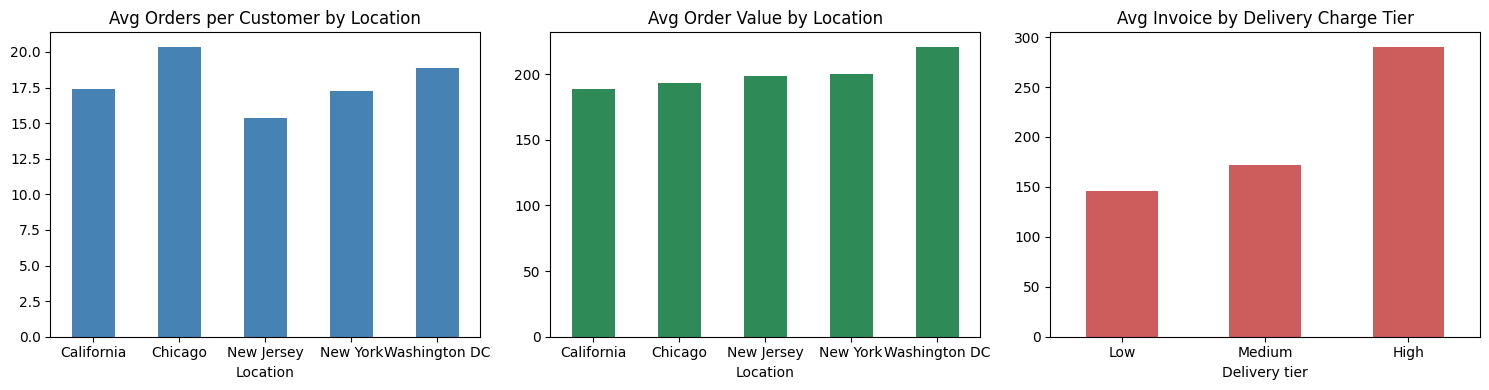

In [123]:
### Q15
cb = txn.groupby('CustomerID').agg(
    Orders=('Transaction_ID','nunique'),
    AOV=('Invoice','mean'),
    Spend=('Invoice','sum'))
cb = cb.join(cust.set_index('CustomerID')[['Gender','Location','Tenure_Months']])
print(cb.groupby('Location')[['Orders','AOV','Spend']].mean().round(1))
print(cb.groupby('Gender')[['Orders','AOV','Spend']].mean().round(1))
for col in ['Orders','AOV']:
  kw = stats.kruskal(*[g[col].values for _, g in cb.groupby('Location')])
  mw = stats.mannwhitneyu(*[g[col].values for _, g in cb.groupby('Gender')])
  print(f"{col}: Location Kruskal p={kw.pvalue:.4g} | Gender Mann-Whitney p={mw.pvalue:.4g}")

# delivery charge tiers (tertiles, transaction level)
txn['Del_Tier'] = pd.qcut(txn['Delivery'].rank(method='first'), 3, labels=['Low','Medium','High'])
tier = txn.groupby('Del_Tier').agg(avg_delivery=('Delivery','mean'),
                                   avg_invoice=('Invoice','mean'),
                                   avg_qty=('Qty','mean'), txns=('Invoice','count'))
print(tier.round(2))
print("Delivery tiers Kruskal (invoice): p =", round(stats.kruskal(*[g['Invoice'].values for _, g in txn.groupby('Del_Tier')]).pvalue,4))
fig, ax = plt.subplots(1,3, figsize=(15,4))
cb.groupby('Location')['Orders'].mean().plot(kind='bar', ax=ax[0], color='steelblue')
ax[0].set_title('Avg Orders per Customer by Location')
cb.groupby('Location')['AOV'].mean().plot(kind='bar', ax=ax[1], color='seagreen')
ax[1].set_title('Avg Order Value by Location')
tier['avg_invoice'].plot(kind='bar', ax=ax[2], color='indianred')
ax[2].set_title('Avg Invoice by Delivery Charge Tier')
for a in ax:
   a.tick_params(axis='x', rotation=0)
ax[0].set_xlabel('Location')
ax[1].set_xlabel('Location')
ax[2].set_xlabel('Delivery tier')
plt.tight_layout()
plt.show()

**Q15:Do purchase behaviors (e.g., order frequency, order value) vary significantly across different demographic groups or pricing factors (e.g., delivery charges)?Test for differences in purchase behavior across locations, age groups, or delivery charge tiers. How can these insights inform personalized marketing and pricing strategies?**
Q15 Insight: Purchase behaviour does not differ significantly by location. Chicago has the most orders per customer (20.4) and Washington DC the highest order value (220.9), but neither difference is significant (Kruskal-Wallis p = 0.26 for orders, p = 0.69 for order value). Gender shows a very small gap: males have a slightly higher order value (197.8 vs 194.1, p = 0.047, about +2%) and orders are not significantly different (p = 0.069). Delivery-charge tiers differ strongly (p < 0.001): low-tier orders average 2.2 units and 146 invoice, medium 3.5 units and 172, high 21.2 units and 290. This is mostly because delivery is charged per item line, so bigger baskets automatically carry a higher delivery charge.
Q15 Recommendations: (1) Do not build separate location-based pricing, as the data does not support it. Run one national strategy and localise only the creative. (2) Treat Washington DC as the premium market (highest order value) for upsell, and Chicago as the frequency market for subscriptions and repeat offers. (3) Plan delivery pricing by basket size, not by demographics.

Tenure vs Orders: Spearman r=0.009, p=0.7357 | Tenure vs Spend: r=0.008, p=0.7542
               customers  avg_orders  avg_spend
Tenure_Group                                   
(1.999, 14.0]        378        17.6     3511.7
(14.0, 26.0]         380        17.3     3427.8
(26.0, 38.0]         359        20.1     4156.9
(38.0, 50.0]         351        17.5     3632.5


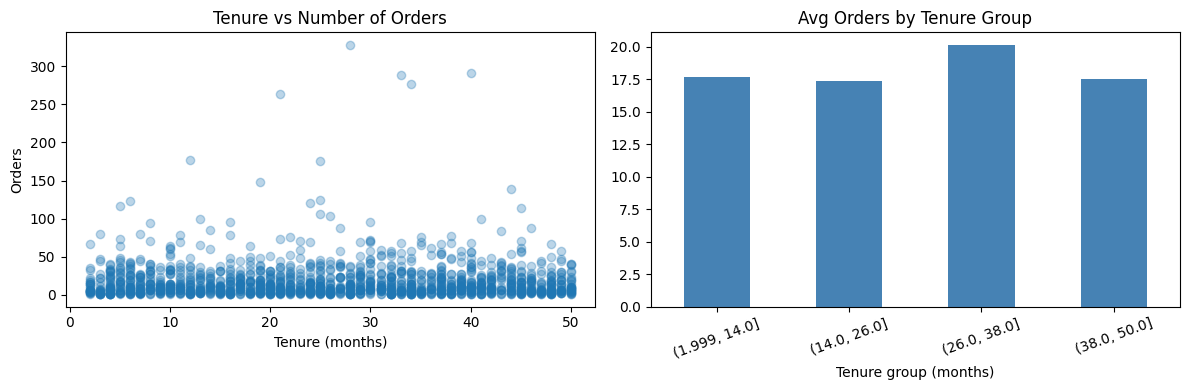

In [124]:
### Q16
r, pr = stats.spearmanr(cb['Tenure_Months'], cb['Orders'])
r2, pr2 = stats.spearmanr(cb['Tenure_Months'], cb['Spend'])
print(f"Tenure vs Orders: Spearman r={r:.3f}, p={pr:.4g} | Tenure vs Spend: r={r2:.3f}, p={pr2:.4g}")

cb['Tenure_Group'] = pd.qcut(cb['Tenure_Months'], 4, duplicates='drop')
tg = cb.groupby('Tenure_Group').agg(customers=('Orders','count'), avg_orders=('Orders','mean'), avg_spend=('Spend','mean'))
print(tg.round(1))

fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].scatter(cb['Tenure_Months'], cb['Orders'], alpha=.3); ax[0].set_title('Tenure vs Number of Orders')
ax[0].set_xlabel('Tenure (months)'); ax[0].set_ylabel('Orders')
tg['avg_orders'].plot(kind='bar', ax=ax[1], color='steelblue'); ax[1].set_title('Avg Orders by Tenure Group')
ax[1].set_xlabel('Tenure group (months)'); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

**Does customer tenure impact purchase frequency?Analyze the relationship between customer tenure and purchase frequency. How can this insight be used to improve customer engagement and retention strategies?**
Q16 Insight: Tenure has no relationship with purchase frequency. The Spearman correlation between tenure and number of orders is 0.009 (p = 0.74), and with total spend it is 0.008 (p = 0.75). Across the four tenure groups, average orders stay at 17-20 per customer (2-14 months: 17.6, 14-26: 17.3, 26-38: 20.1, 38-50: 17.5), with no upward trend. Longer-tenured customers are not more active.
Q16 Recommendations: (1) Do not assume loyalty builds over time, because it needs active programs. (2) Create tenure-based milestones (6, 12, 24 months) with rewards that nudge a next purchase. (3) Run re-engagement campaigns for older customers, whose activity is the same as new ones.

Zero delivery charge share: 0.6 %
Delivery vs Qty: Spearman r=0.709, p=0
Delivery vs Invoice: Spearman r=0.199, p=1.915e-235
          avg_delivery  avg_invoice  avg_qty  txns  delivery_pct
Del_Tier                                                        
Low               5.94       146.07     2.17  8877         10.94
Medium            8.82       171.73     3.45  8877         12.56
High             47.94       290.22    21.20  8877         26.06


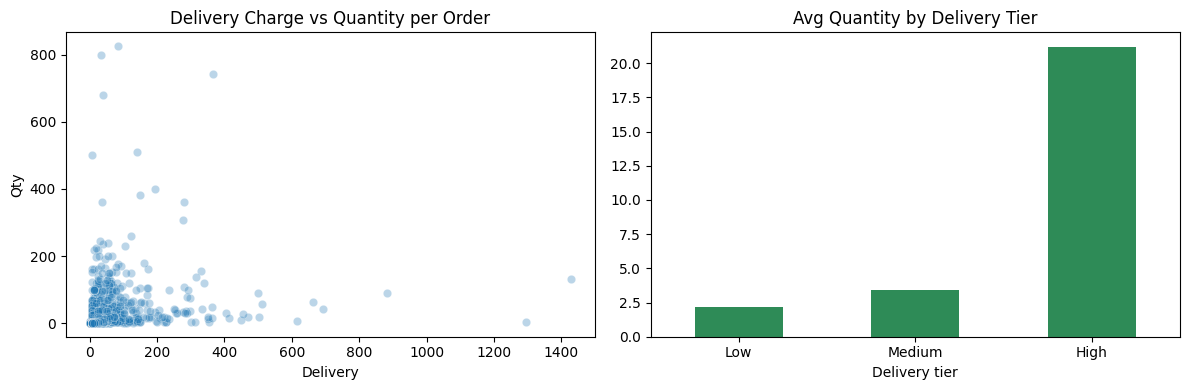

In [125]:
### Q17
print("Zero delivery charge share:", round((txn['Delivery']==0).mean()*100,1), "%")
for col in ['Qty','Invoice']:
    r, p = stats.spearmanr(txn['Delivery'], txn[col])
    print(f"Delivery vs {col}: Spearman r={r:.3f}, p={p:.4g}")
txn['Del_%_of_Invoice'] = txn['Delivery']/txn['Invoice']*100
print(tier.assign(delivery_pct=txn.groupby('Del_Tier')['Del_%_of_Invoice'].mean()).round(2))

fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.scatterplot(x='Delivery', y='Qty', data=txn.sample(min(5000,len(txn)), random_state=1), alpha=.3, ax=ax[0])
ax[0].set_title('Delivery Charge vs Quantity per Order')
tier[['avg_qty']].plot(kind='bar', ax=ax[1], color='seagreen', legend=False)
ax[1].set_title('Avg Quantity by Delivery Tier')
ax[1].set_xlabel('Delivery tier')
ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Analyze the relationship between delivery charges and order behavior. Are there opportunities to optimize delivery pricing to increase order quantities or revenue?**
Q17 Insight: Only 0.6% of transactions have zero delivery charge. Delivery charge rises with order size (Spearman r = 0.71 with quantity, r = 0.20 with invoice value). Delivery is 10.9% of the invoice in the low tier, 12.6% in the medium tier and about 26% in the high tier, so large orders carry the heaviest delivery burden. This reflects per-line delivery charging, so it shows how delivery is structured, not that higher charges make people buy more.
Q17 Recommendations: (1) Test a free-delivery threshold (for example near the 170-200 invoice range) to push small orders (146 average) to a higher basket. (2) Cap or tier delivery for bulk orders, where it reaches about a quarter of the invoice and may deter repeat bulk buying. (3) A/B test delivery pricing before rolling it out, since this data cannot prove cause and effect.

                       GST     revenue  avg_qty  avg_price        tax  \
Product_Category                                                        
Nest-USA              0.10  2721645.76     1.53     124.33  238364.15   
Apparel               0.18   827829.21     1.79      19.79   99299.71   
Nest                  0.05   520653.67     1.29     194.22   24027.18   
Office                0.10   381945.27    13.57       3.77   25772.49   
Drinkware             0.18   272621.96     8.76      10.70   33939.73   
Bags                  0.18   193626.61     8.12      29.83   25624.31   
Lifestyle             0.18   125276.00     8.05       3.86   12514.55   
Notebooks & Journals  0.05   122419.32    12.76      11.76    5076.67   
Nest-Canada           0.10    76245.76     1.48     157.24    6667.53   
Headgear              0.05    57861.49     4.58      15.88    2399.90   
Gift Cards            0.05    19447.44     1.30     111.36     926.07   
Google                0.10    13168.81     5.48    

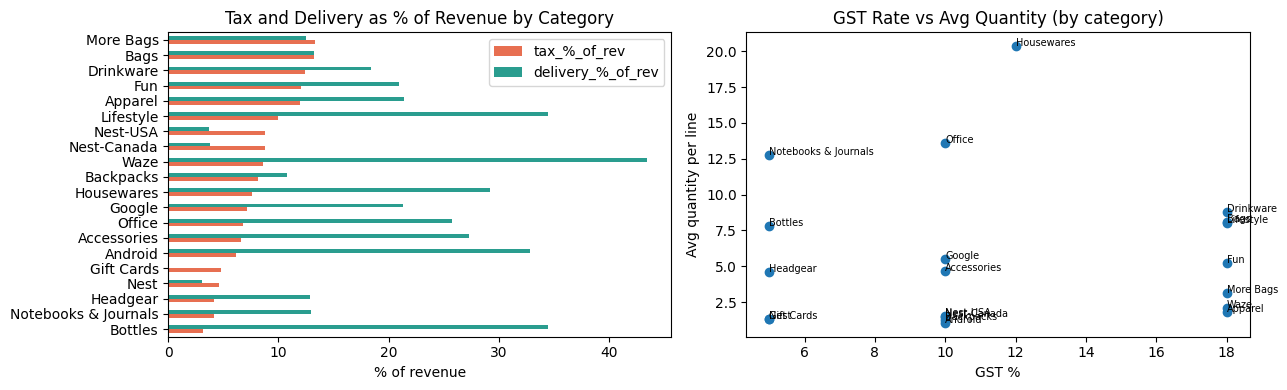

In [126]:
### Q18
df['Tax_Amt'] = df['Quantity']*df['Avg_Price']*(1-df['Discount_pct']/100)*df['GST']
cx = df.groupby('Product_Category').agg(GST=('GST','mean'), revenue=('Invoice_Value','sum'),
        avg_qty=('Quantity','mean'), avg_price=('Avg_Price','mean'),
        tax=('Tax_Amt','sum'), delivery=('Delivery_Charges','sum'))
cx['tax_%_of_rev'] = cx['tax']/cx['revenue']*100
cx['delivery_%_of_rev'] = cx['delivery']/cx['revenue']*100
print(cx.sort_values('revenue', ascending=False).round(2))
print("Total tax % of revenue:", round(df['Tax_Amt'].sum()/df['Invoice_Value'].sum()*100,2),
      "| Total delivery % of revenue:", round(df['Delivery_Charges'].sum()/df['Invoice_Value'].sum()*100,2))
r, p = stats.spearmanr(cx['GST'], cx['avg_qty']); print(f"GST rate vs avg qty (category level): r={r:.3f}, p={p:.3f}")
print(df.groupby('GST').agg(lines=('Quantity','count'), avg_qty=('Quantity','mean'), avg_invoice=('Invoice_Value','mean')).round(2))

fig, ax = plt.subplots(1,2, figsize=(13,4))
cx[['tax_%_of_rev','delivery_%_of_rev']].sort_values('tax_%_of_rev').plot(kind='barh', ax=ax[0], color=['#e76f51','#2a9d8f'])
ax[0].set_title('Tax and Delivery as % of Revenue by Category')
ax[0].set_xlabel('% of revenue')
ax[0].set_ylabel('')
ax[1].scatter(cx['GST']*100 if cx['GST'].max()<1 else cx['GST'], cx['avg_qty'])
for n, rw in cx.iterrows():
    ax[1].annotate(n, (rw['GST']*100 if cx['GST'].max()<1 else rw['GST'], rw['avg_qty']), fontsize=7)
ax[1].set_title('GST Rate vs Avg Quantity (by category)')
ax[1].set_xlabel('GST %'); ax[1].set_ylabel('Avg quantity per line')
plt.tight_layout()
plt.show()

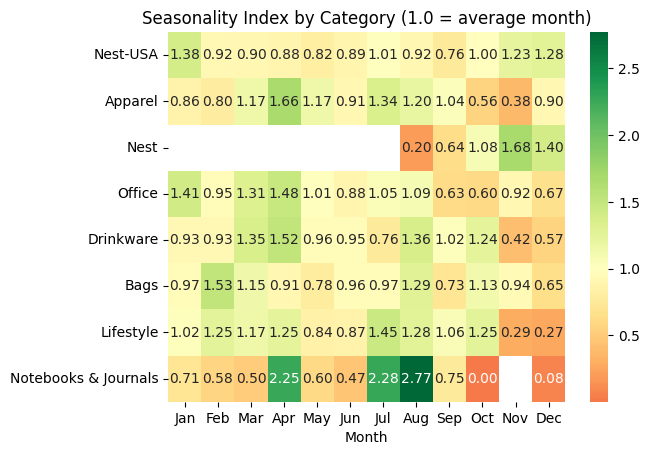

                     peak  peak_idx  low  low_idx
Product_Category                                 
Nest-USA              Jan      1.38  Sep     0.76
Apparel               Apr      1.66  Nov     0.38
Nest                  Nov      1.68  Aug     0.20
Office                Apr      1.48  Oct     0.60
Drinkware             Apr      1.52  Nov     0.42
Bags                  Feb      1.53  Dec     0.65
Lifestyle             Jul      1.45  Dec     0.27
Notebooks & Journals  Aug      2.77  Oct     0.00


In [127]:
### Q19 by categories

pc = df.pivot_table(index='Product_Category', columns='MonthNum', values='Invoice_Value', aggfunc='sum')
pc.columns = mlabels
top_cats = pc.sum(axis=1).sort_values(ascending=False).head(8).index
si = pc.loc[top_cats].div(pc.loc[top_cats].mean(axis=1), axis=0) # 1.0 = average monthplt.figure(figsize=(11,4.5))
sns.heatmap(si, annot=True, fmt='.2f', cmap='RdYlGn', center=1)
plt.title('Seasonality Index by Category (1.0 = average month)')
plt.xlabel('Month')
plt.ylabel('')
plt.show()
print(pd.DataFrame({'peak':si.idxmax(axis=1), 'peak_idx':si.max(axis=1).round(2),'low':si.idxmin(axis=1), 'low_idx':si.min(axis=1).round(2)}))

**Identify seasonal trends in sales by category and location. How can the company prepare for peak and off-peak seasons to maximize revenue?**
Insight: Category peaks differ: Apparel, Office and Drinkware peak in April (index 1.66, 1.48, 1.52), Bags in February (1.53), Lifestyle in July (1.45), Notebooks & Journals in August (2.77) and Nest-USA in January (1.38), with a second peak in Nov-Dec (1.23, 1.28). Apparel, Drinkware, Lifestyle and Bags weaken in Nov-Dec (0.27-0.65). Nest was sold only from August, so its Nov peak (1.68) is a launch ramp-up, not true seasonality. Notebooks & Journals had no sales in Oct-Nov. By location, California, Chicago and New Jersey peak in December (1.40, 1.31, 1.43), New York in November (1.34), and Washington DC peaks early in the year (Feb 1.74). May-Jun is the weak stretch across locations (DC drops to 0.29 in May).
Recommendations: (1) Stock Apparel, Office and Drinkware ahead of April, and Nest-USA and Nest ahead of Nov-Dec. (2) In weak months, use promotions or bundles, for example Apparel and Drinkware in Nov-Dec, to avoid an idle period. (3) Time regional campaigns differently: holiday pushes in California, Chicago, New Jersey and New York, and a New Year push in Washington DC. (4) Investigate the zero sales of Notebooks & Journals in Oct-Nov, which may be a stock-out.
Note: only one year of data is available, so these are 2019 patterns to be validated with more years.

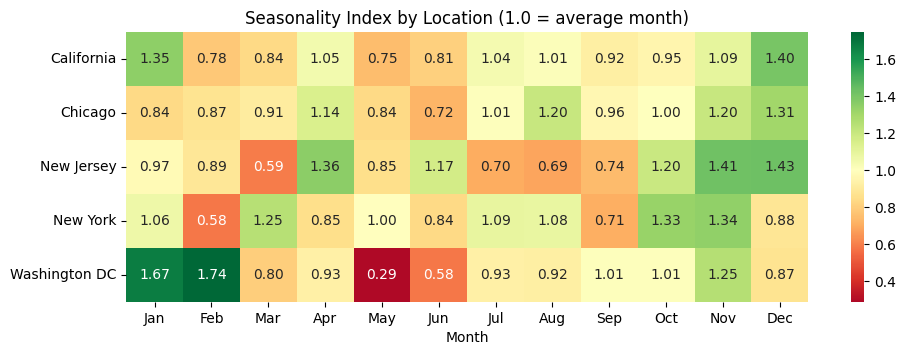

              peak  low    revenue
Location                          
California     Dec  May  1668590.0
Chicago        Dec  Jun  1876541.0
New Jersey     Dec  Mar   467753.0
New York       Nov  Feb  1089542.0
Washington DC  Feb  May   294933.0


In [128]:
### 19 By location
pl = df.pivot_table(index='Location', columns='MonthNum', values='Invoice_Value', aggfunc='sum')
pl.columns = mlabels
sl = pl.div(pl.mean(axis=1), axis=0)
plt.figure(figsize=(11,3.5))
sns.heatmap(sl, annot=True, fmt='.2f', cmap='RdYlGn', center=1)
plt.title('Seasonality Index by Location (1.0 = average month)')
plt.xlabel('Month')
plt.ylabel('')
plt.show()
print(pd.DataFrame({'peak':sl.idxmax(axis=1), 'low':sl.idxmin(axis=1), 'revenue':pl.sum(axis=1).round(0)}))


               mean    median        sum  index_vs_avg
Monday      7936.19   7299.15  412681.89          0.54
Tuesday     8494.98   8643.97  450233.69          0.57
Wednesday  18390.55  17714.35  956308.44          1.24
Thursday   18740.61  17926.37  974511.96          1.27
Friday     19206.21  17295.49  998722.69          1.30
Saturday   15214.11  13976.78  791133.56          1.03
Sunday     15649.36  14942.70  813766.51          1.06
Top 5 days:
 2019-04-05    59951.0
2019-11-27    56662.0
2019-04-18    54471.0
2019-07-18    42947.0
2019-08-02    40533.0
Name: Invoice_Value, dtype: float64
Bottom 5 days:
 2019-05-28    1994.0
2019-08-20    3268.0
2019-02-05    3875.0
2019-09-02    4424.0
2019-05-27    4659.0
Name: Invoice_Value, dtype: float64
Weekday avg: 14530 | Weekend avg: 15432 | Mann-Whitney p = 0.0118
Kruskal across 7 weekdays: p = 0.0


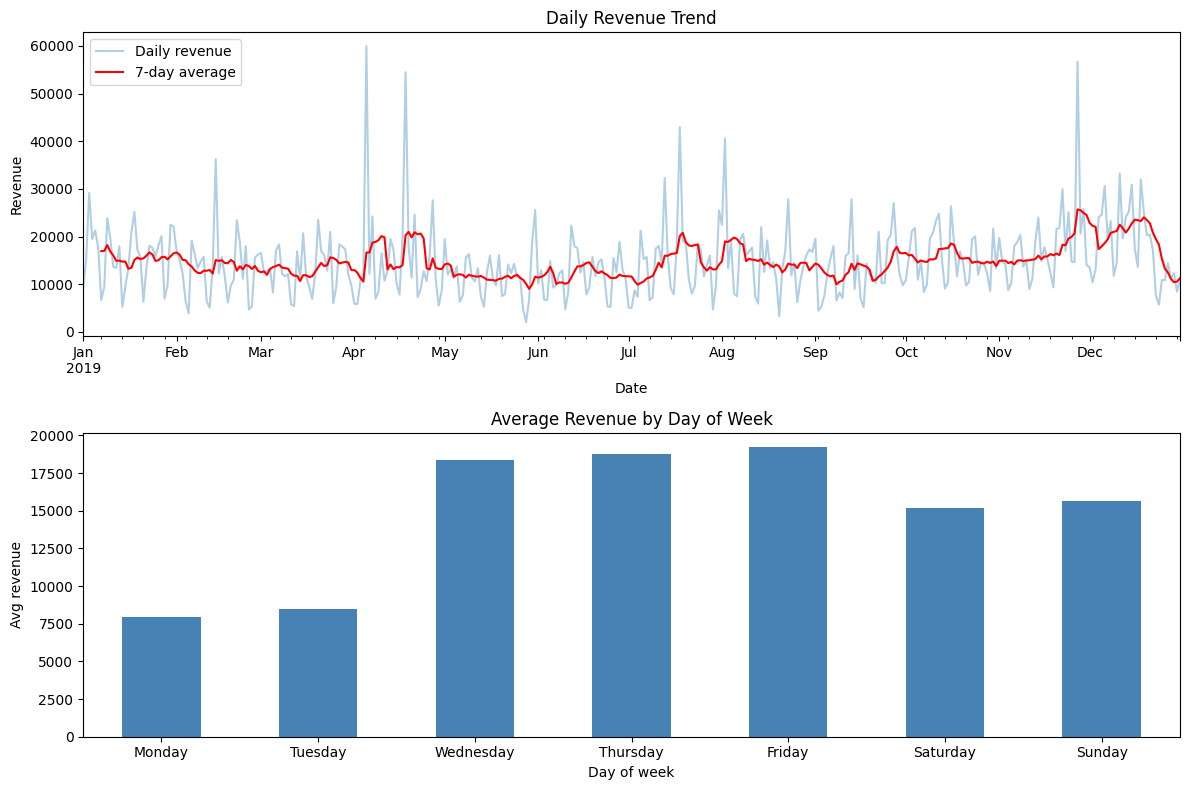

In [129]:
### Q20: daily
daily = df.groupby('Transaction_Date')['Invoice_Value'].sum()
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()), fill_value=0)
days = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow = daily.groupby(daily.index.day_name()).agg(['mean','median','sum']).loc[days]
dow['index_vs_avg'] = dow['mean']/daily.mean()
print(dow.round(2))
print("Top 5 days:\n", daily.nlargest(5).round(0))
print("Bottom 5 days:\n", daily.nsmallest(5).round(0))
wk = daily[daily.index.dayofweek<5]
we = daily[daily.index.dayofweek>=5]
print("Weekday avg:", round(wk.mean()), "| Weekend avg:", round(we.mean()),"| Mann-Whitney p =", round(stats.mannwhitneyu(wk, we).pvalue,4))
print("Kruskal across 7 weekdays: p =", round(stats.kruskal(*[daily[daily.index.dayofweek==i] for i in range(7)]).pvalue,4))
fig, ax = plt.subplots(2,1, figsize=(12,8))
daily.plot(ax=ax[0], alpha=.35, label='Daily revenue')
daily.rolling(7).mean().plot(ax=ax[0], color='red', label='7-day average')
ax[0].set_title('Daily Revenue Trend')
ax[0].set_xlabel('Date')
ax[0].set_ylabel('Revenue')
ax[0].legend()
dow['mean'].plot(kind='bar', ax=ax[1], color='steelblue')
ax[1].set_title('Average Revenue by Day of Week')
ax[1].set_xlabel('Day of week')
ax[1].set_ylabel('Avg revenue')
ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Analyze daily sales trends to identify high-performing and low-performing days. What strategies can be implemented to boost sales on slower days?**
nsight: Daily revenue averages ~14.8K but is very uneven. Wednesday to Friday are strongest (Friday 19.2K average, index 1.30), weekends are about average (Sat 15.2K, Sun 15.6K), and Monday and Tuesday are weakest at roughly 8K, about half of the strong days. Days of the week differ significantly (Kruskal-Wallis p < 0.001). Weekend revenue is slightly higher than weekday (15.4K vs 14.5K, p = 0.012), but that comparison hides the Mon/Tue weakness. The top days are single spikes: 5 Apr (59.9K, about 4x an average day), 27 Nov (56.7K, the day before Thanksgiving), 18 Apr (54.5K), 18 Jul (42.9K) and 2 Aug (40.5K). Four of the five lowest days fall on Mon/Tue, and two are US holidays (27 May Memorial Day with 4.7K, 2 Sep Labor Day with 4.4K). The 7-day average is mostly flat at 10-15K and rises to ~25K in late Nov-Dec.
Recommendations: (1) Boost Mon/Tue with "Monday deals", email and app pushes and free delivery on those days. (2) Study what drove the Apr 5, Apr 18, Jul 18 and Aug 2 spikes (campaign, coupon or product launch) and repeat them on slow days. (3) Make sure stock and support are ready before pre-holiday spikes like 27 Nov. (4) Plan lighter staffing or low-cost promotions around holidays that fall on Mondays.